<h1> The lab was done by Yatsenko Mariana K-13 <h1>
Variant 99
<h1>Pandas 2.2.0,matplotlib 3.8.3,python 3.11.8<h1>


<h2> Data processing and visualization<h2>

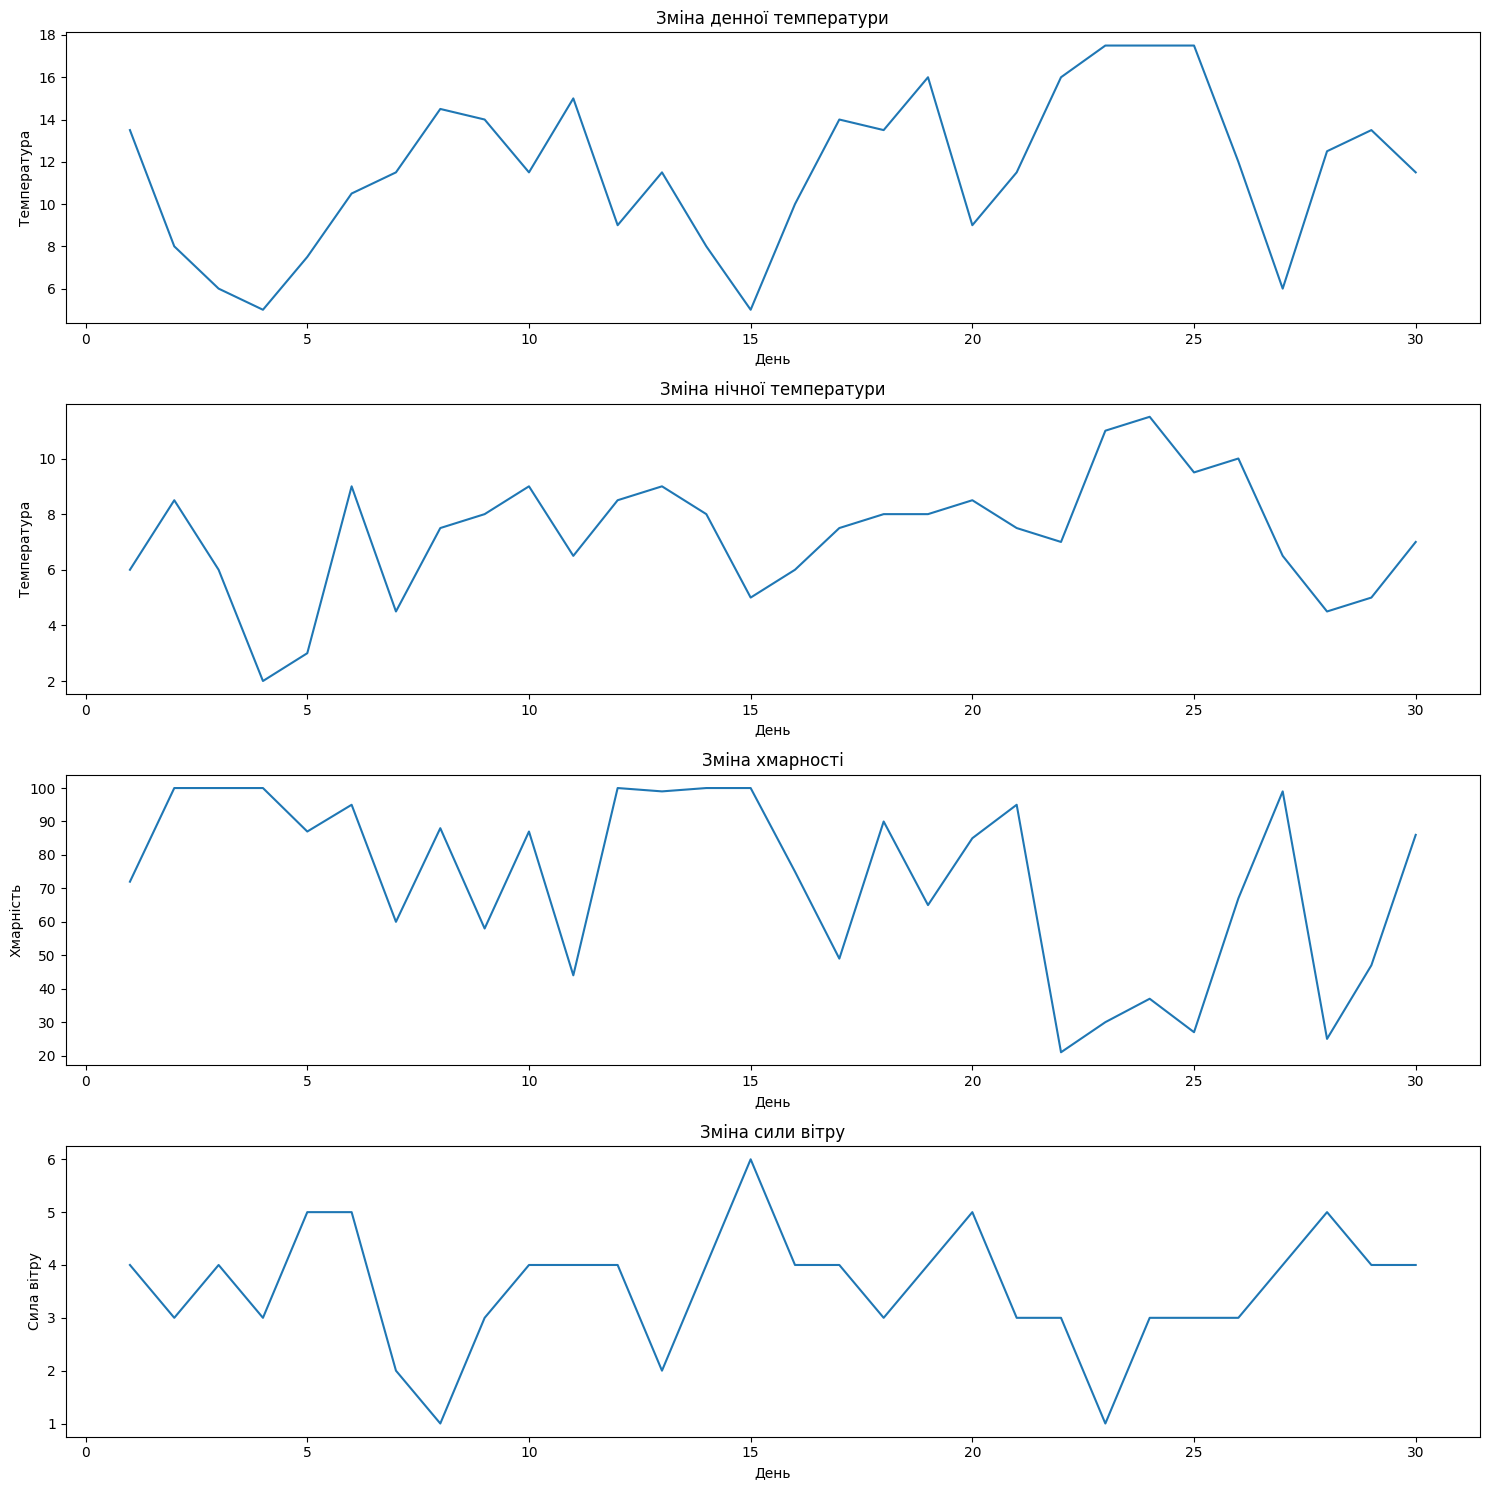

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
weather = pd.read_csv('https://drive.usercontent.google.com/download?id=1WOkgekeV4h5yU4ASGshGuPg5mb7buyUk&export=download&authuser=0&confirm=t&uuid=5f2b28bf-be9d-4ac9-be76-8ffc24fdb15d&at=ALoNOgmy3gAqFnOYWQlDnN89JVzF:1746979392371')
period = weather.loc[weather['період'].str.split('-').str[1].astype(int) == (99%12+1)]
fig, axs = plt.subplots(4, 1, figsize=(15, 15))

axs[0].plot(period['день'], period['денна температура повітря'].str.replace('°C', '').astype(float))
axs[0].set_title('Зміна денної температури')
axs[0].set_xlabel('День')
axs[0].set_ylabel('Температура')

axs[1].plot(period['день'], period['нічна температура повітря'].str.replace('°C', '').astype(float))
axs[1].set_title('Зміна нічної температури')
axs[1].set_xlabel('День')
axs[1].set_ylabel('Температура')

axs[2].plot(period['день'], period['хмарність'].str.replace('%', '').astype(float))
axs[2].set_title('Зміна хмарності')
axs[2].set_xlabel('День')
axs[2].set_ylabel('Хмарність')

axs[3].plot(period['день'], period['сила вітру'].str.replace(' м/с', '').astype(float))
axs[3].set_title('Зміна сили вітру')
axs[3].set_xlabel('День')
axs[3].set_ylabel('Сила вітру')

plt.tight_layout()
plt.show()

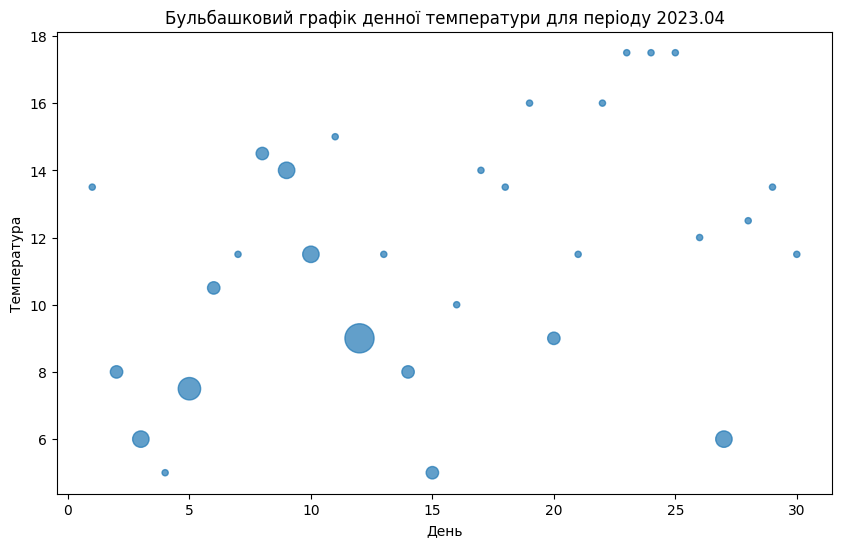

In [23]:
period.loc[period['опади'].str.split(' ').str[0] == '-', 'опади'] = '0'
rainfall = period['опади'].str.split(' ').str[0].astype(float)

plt.figure(figsize=(10, 6))
plt.scatter(period['день'],period['денна температура повітря'].str.replace('°C', '').astype(float),s=rainfall * 60 + 20,alpha=0.7)
plt.xlabel('День')
plt.ylabel('Температура')
plt.title('Бульбашковий графік денної температури для періоду 2023.04')
plt.show()

In [24]:
for i in range(1, 13):
    month = weather.loc[weather['період'].str.split('-').str[1].astype(int) == i]
    day_temp = month['денна температура повітря'].str.replace('°C', '').astype(float)
    night_temp = month['нічна температура повітря'].str.replace('°C', '').astype(float)
    temp_diff = day_temp - night_temp
    monthly_deviation = temp_diff.mean()
    print(f'Середнє відхилення у {i}-му місяці: {monthly_deviation:.2f}')


Середнє відхилення у 1-му місяці: 2.47
Середнє відхилення у 2-му місяці: 3.09
Середнє відхилення у 3-му місяці: 4.69
Середнє відхилення у 4-му місяці: 4.35
Середнє відхилення у 5-му місяці: 7.45
Середнє відхилення у 6-му місяці: 8.32
Середнє відхилення у 7-му місяці: 8.66
Середнє відхилення у 8-му місяці: 9.40
Середнє відхилення у 9-му місяці: 5.42
Середнє відхилення у 10-му місяці: 5.05
Середнє відхилення у 11-му місяці: 3.20
Середнє відхилення у 12-му місяці: 2.60


In [25]:
day_temp = weather['денна температура повітря'].str.replace('°C', '').astype(float)
night_temp = weather['нічна температура повітря'].str.replace('°C', '').astype(float)
temp_diff = day_temp - night_temp
max_diff_indices = temp_diff.idxmax()
print(weather.loc[max_diff_indices])

день                              26
хмарність                         9%
опади                              -
денна температура повітря     36.5°C
нічна температура повітря     20.5°C
сила вітру                     4 м/с
період                       2022-08
Name: 267, dtype: object


In [26]:
wind_speed = period['сила вітру'].str.replace(' м/с', '').astype(float)
windiest_days_indices = wind_speed.nlargest(4).index
print(period.loc[windiest_days_indices])

    день хмарність   опади денна температура повітря  \
14    15      100%  1 м.м.                     5.0°C   
4      5       87%  4 м.м.                     7.5°C   
5      6       95%  1 м.м.                    10.5°C   
19    20       85%  1 м.м.                     9.0°C   

   нічна температура повітря сила вітру   період  
14                     5.0°C      6 м/с  2023-04  
4                      3.0°C      5 м/с  2023-04  
5                      9.0°C      5 м/с  2023-04  
19                     8.5°C      5 м/с  2023-04  


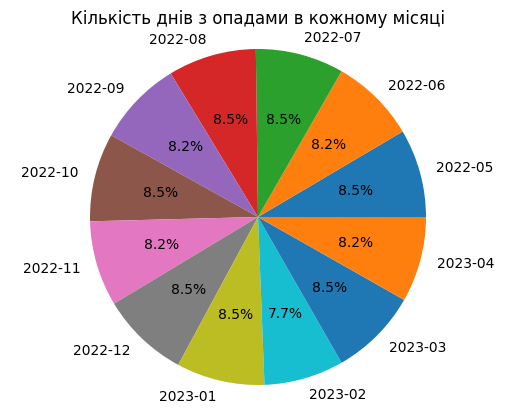

In [27]:
rainy_days = weather[weather['опади'] != '0'].groupby(weather['період']).size()
plt.pie(rainy_days, labels=rainy_days.index, autopct='%1.1f%%')
plt.title('Кількість днів з опадами в кожному місяці')
plt.axis('equal')
plt.show()


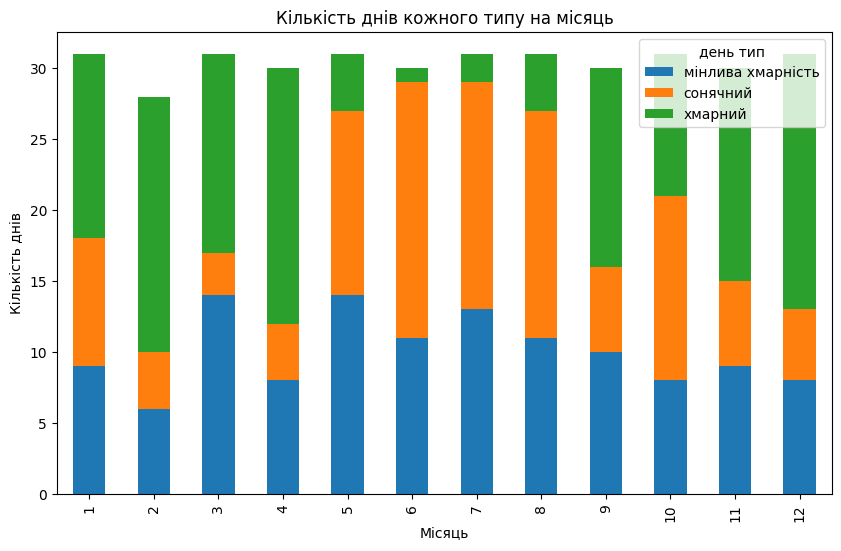

In [28]:
weather['хмарність'] = weather['хмарність'].str.replace('%', '').astype(float)
weather['день тип'] = weather['хмарність'].apply(lambda x: 'хмарний' if x > 70 else 'сонячний' if x < 35 else 'мінлива хмарність')

days_per_month = weather.groupby([weather['період'].str.split('-').str[1].astype(int), 'день тип']).size().unstack().fillna(0)

days_per_month.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.xlabel('Місяць')
plt.ylabel('Кількість днів')
plt.title('Кількість днів кожного типу на місяць')
plt.show()

In [29]:
for month in range(1, 13):
    p = weather[weather['період'].str.split('-').str[1].astype(int) == month]
    rainfall = p[p['опади'].str.split(' ').str[0] != '-']
    sunny_days = p[p['хмарність'] < 35]
    if sunny_days.shape[0] > rainfall.shape[0]:
        print(f"Місяць {month}: {p['період'].iloc[0]}")

Місяць 1: 2023-01
Місяць 5: 2022-05
Місяць 6: 2022-06
Місяць 7: 2022-07
Місяць 8: 2022-08
Місяць 10: 2022-10


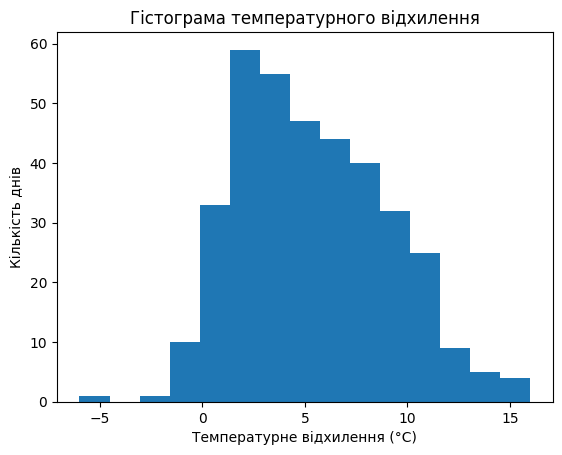

In [30]:
plt.hist(weather['денна температура повітря'].str.replace('°C', '').astype(float) - weather['нічна температура повітря'].str.replace('°C', '').astype(float),bins=15)
plt.xlabel('Температурне відхилення (°C)')
plt.ylabel('Кількість днів')
plt.title('Гістограма температурного відхилення')
plt.show()